In [2]:
import pandas as pd 
import numpy as np 
from scipy.stats import pearsonr 
import matplotlib.pyplot as plt
import seaborn as sns 
from datasets.Harmonized_Datasets import harmonize

In [3]:
mf_ad = harmonize()['Moffitt']

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


DeCampos Annotated data found!
Number of Harmonized Genes: 18672


In [4]:
expr_df = mf_ad.to_df()
auc = mf_ad.obs['ABT-199']

results = {}
for col in expr_df.columns:
    corr_result = pearsonr(expr_df[col], auc)
    results[col] = {'pval': corr_result.pvalue, 'pearson_correlation': corr_result.statistic}


/tmp/ipykernel_61586/2485590926.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_result = pearsonr(expr_df[col], auc)


In [5]:

results_df = pd.DataFrame(results).T.sort_values(by='pearson_correlation')
results_df = results_df[results_df['pearson_correlation'].notna()].sort_values(by='pearson_correlation')

In [6]:
results_df.head(30)

,pval,pearson_correlation
ZBTB20,0.000008,-0.409272
TM7SF2,0.000026,-0.388071
IQCN,0.000035,-0.382103
FOXO1,0.000039,-0.379887
LRRK2,0.000071,-0.368074
TBC1D30,0.000085,-0.364173
DIRAS1,0.000112,-0.358448
RASD1,0.000118,-0.357415
KLRG2,0.000118,-0.357402
SI,0.000120,-0.356929


In [7]:
results_df.tail(30)

,pval,pearson_correlation
MAGEA1,0.001316,0.301216
MAGEA6,0.001311,0.301305
CCDC30,0.001280,0.301912
IFNAR2,0.001213,0.303284
DIXDC1,0.001213,0.303289
TDO2,0.001203,0.303507
HTR2C,0.001133,0.305035
CENPA,0.001061,0.306679
RASSF5,0.001030,0.307439
AP3B2,0.000920,0.310264


In [8]:
results_df.loc['BCL2']
[1, 2, 3]

[1, 2, 3]

In [15]:
results_df['gene'] = results_df.index

(-1.0, 1.0)

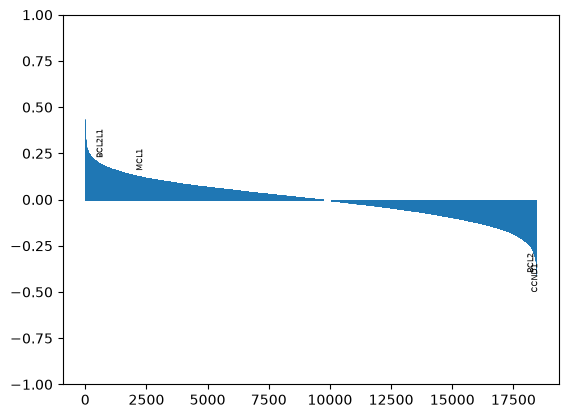

In [ ]:
d = results_df.sort_values("pearson_correlation", ascending=False).reset_index(drop=True)
r = d["pearson_correlation"].to_numpy()

plt.vlines(np.arange(len(d)), 0, r, linewidth=0.6)

for g in ["BCL2L1", "MCL1", "BCL2", "CCND1"]:
    i = d.index[d["gene"] == g][0]    
    plt.text(i, r[i] + (0.03 if r[i] > 0 else -0.03), g,
             rotation=90, fontsize=6, ha="center",
             va="bottom" if r[i] > 0 else "top")

plt.ylim(-1, 1)
